In [1]:
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "EDA_COCO_vs_VizWiz_Report.md").is_file())
assert (ROOT / "EDA_COCO_vs_VizWiz_Report.md").is_file()

# EDA phục vụ khái quát hóa HGAI sang VLM nhỏ

COCO val2014 là tập đánh giá chính. SmolVLM2-2.2B và TinyLLaVA-3.1B là hai mô hình chính; LLaVA-1.5-7B là mốc kiểm chứng. **CHAIR là thước đo chính, POPE kiểm tra chéo**; VizWiz cung cấp bối cảnh về khác biệt dữ liệu.

Năm phát hiện chính:

1. Toàn bộ **40.504/40.504** ảnh COCO val2014 giải mã được; **35.504** ảnh cũng có ID trong train2017.
2. Mix SFT LLaVA khớp **16.618/40.504** ID COCO khi tính cả alias VG/GQA; recipe ShareGPT4V khớp **37.527/40.504**, để lại **2.977** ảnh chưa khớp nguồn đã kiểm tra.
3. SmolVLM2 tạo **1.053 token ảnh** cho ảnh 640×480 khi chia 13 ô, còn tắt chia ô có **81 token**; TinyLLaVA pad384 có **729 token**.
4. Center crop LLaVA làm **5.750/116.592 (4,9%)** cặp ảnh–lớp mất mọi instance khỏi vùng nhìn thấy.
5. Quy tắc layer v1 trên **20 ảnh dev SmolVLM2** trả “không tìm thấy ranh giới”; phép dò α trên 20 ảnh cho thấy ở α=0,10 có **4/20** caption chia ô mặc định co quá nửa.

## 1. Dữ liệu và nguồn huấn luyện

COCO val2014 có 40.504 ảnh và 202.654 caption. Kiểm tra toàn vẹn giải mã được **40.504/40.504 ảnh**; đối chiếu ID COCO cho thấy **35.504/40.504** ảnh val2014 cũng nằm trong train2017. Đây là giao nhau của hai split, không tự chứng minh VLM đã học các ảnh này.

**SFT** là giai đoạn fine-tune có giám sát; **recipe** là công thức phối trộn nguồn huấn luyện, không phải danh sách chắc chắn từng mẫu mà checkpoint đã thấy. LLaVA được kiểm tra bằng đường dẫn COCO trực tiếp trong mix SFT 665K và nối `image_id` Visual Genome/GQA sang `coco_id`: 5.741 ID trực tiếp, 10.877 ID chỉ qua alias, hợp là 16.618. TinyLLaVA được đối chiếu riêng với recipe LLaVA và ShareGPT4V, gồm SFT và pretraining có ID công khai. Với SmolVLM2, tám shard ID của hai slice OneVision ShareGPT4V-COCO/LLaVA được quét; khớp chỉ đánh dấu ứng viên trong nguồn upstream. Các nguồn khác, lịch sử mô hình nền và mẫu thực sự được rút từ recipe SmolVLM2 chưa có manifest đầy đủ. Phép nối ID vì vậy không chứng minh hai VLM nhỏ chưa từng thấy ảnh.

### Khớp ID theo nguồn đã kiểm tra

<!-- CSV {"path": "eda_results/hgai/report_training_overlap.csv", "title": "Khớp ID theo nguồn đã kiểm tra", "columns": null} -->
| Bộ ảnh | Mô hình hoặc recipe | ID khớp | Giới hạn kết luận |
| :--- | :--- | :--- | :--- |
| val2014 | LLaVA-1.5-7B | 16.618/40.504 (41,0%) | Chỉ xác nhận ID trong SFT đã kiểm tra. |
| val2014 | TinyLLaVA/LLaVA-recipe | 16.618/40.504 (41,0%) | Chỉ xác nhận ID nếu checkpoint dùng recipe này. |
| val2014 | TinyLLaVA/ShareGPT4V-recipe | 37.527/40.504 (92,7%) | Chỉ xác nhận ID nếu checkpoint dùng recipe này. |
| val2014 | SmolVLM2/OneVision-ShareGPT4V-COCO | 15.056/40.504 (37,2%) | Chỉ là ảnh ứng viên ở nguồn upstream. |
| dev_common_unmatched500 | LLaVA-1.5-7B | 0/500 (0,0%) | Chỉ xác nhận ID trong SFT đã kiểm tra. |
| dev_common_unmatched500 | TinyLLaVA/LLaVA-recipe | 0/500 (0,0%) | Chỉ xác nhận ID nếu checkpoint dùng recipe này. |
| dev_common_unmatched500 | TinyLLaVA/ShareGPT4V-recipe | 0/500 (0,0%) | Chỉ xác nhận ID nếu checkpoint dùng recipe này. |
| dev_common_unmatched500 | SmolVLM2/OneVision-ShareGPT4V-COCO | 0/500 (0,0%) | Chỉ là ảnh ứng viên ở nguồn upstream. |
| eval_common_unmatched500 | LLaVA-1.5-7B | 0/500 (0,0%) | Chỉ xác nhận ID trong SFT đã kiểm tra. |
| eval_common_unmatched500 | TinyLLaVA/LLaVA-recipe | 0/500 (0,0%) | Chỉ xác nhận ID nếu checkpoint dùng recipe này. |
| eval_common_unmatched500 | TinyLLaVA/ShareGPT4V-recipe | 0/500 (0,0%) | Chỉ xác nhận ID nếu checkpoint dùng recipe này. |
| eval_common_unmatched500 | SmolVLM2/OneVision-ShareGPT4V-COCO | 0/500 (0,0%) | Chỉ là ảnh ứng viên ở nguồn upstream. |
| eval_random500 | LLaVA-1.5-7B | 205/500 (41,0%) | Chỉ xác nhận ID trong SFT đã kiểm tra. |
| eval_random500 | TinyLLaVA/LLaVA-recipe | 205/500 (41,0%) | Chỉ xác nhận ID nếu checkpoint dùng recipe này. |
| eval_random500 | TinyLLaVA/ShareGPT4V-recipe | 460/500 (92,0%) | Chỉ xác nhận ID nếu checkpoint dùng recipe này. |
| eval_random500 | SmolVLM2/OneVision-ShareGPT4V-COCO | 171/500 (34,2%) | Chỉ là ảnh ứng viên ở nguồn upstream. |
<!-- /CSV -->

## 2. Các bộ ảnh cố định và phân bố object

Ba manifest dùng cho thí nghiệm gồm dev_common_unmatched500, eval_common_unmatched500 và eval_random500. Dev dùng để chọn cấu hình; hai bộ eval dùng để báo kết quả.

### Quy mô và độ khớp nguồn của ba bộ ảnh

<!-- CSV {"path": "eda_results/hgai/report_active_manifests.csv", "title": "Quy mô và độ khớp nguồn của ba bộ ảnh", "columns": null} -->
| Bộ ảnh | Số ảnh | Seed | Khớp nguồn đã kiểm tra | Chưa khớp nguồn đã kiểm tra |
| :--- | :--- | :--- | :--- | :--- |
| eval_random500 | 500 | 42 | 205/500 (41,0%) | 295/500 (59,0%) |
| eval_common_unmatched500 | 500 | 45 | 0/500 (0,0%) | 500/500 (100,0%) |
| dev_common_unmatched500 | 500 | 46 | 0/500 (0,0%) | 500/500 (100,0%) |
<!-- /CSV -->

### Dịch chuyển hình học giữa các bộ ảnh

<!-- CSV {"path": "eda_results/hgai/report_sampling_geometry.csv", "title": "Dịch chuyển hình học giữa các bộ ảnh", "columns": null} -->
| Bộ ảnh | Ảnh dọc | Ảnh vuông | Token ảnh Smol trung bình | Token caption P50 | Lệch tâm vật thể P50 |
| :--- | :--- | :--- | :--- | :--- | :--- |
| eval_random500 | 120/500 (24,0%) | 20/500 (4,0%) | 1.087 | 12 | 0,25 |
| eval_common_unmatched500 | 121/500 (24,2%) | 14/500 (2,8%) | 1.080 | 11 | 0,24 |
| dev_common_unmatched500 | 129/500 (25,8%) | 24/500 (4,8%) | 1.091 | 12 | 0,24 |
<!-- /CSV -->

Nhóm chưa khớp nguồn ShareGPT4V đã kiểm tra gồm 2.977 ảnh. Số lớp trung bình mỗi ảnh là 3,00, so với 2,88 trên toàn val; số instance trung bình tương ứng là 7,41 và 7,21. Hiệu trong hình/bảng là **nhóm 2.977 trừ toàn val2014**; CI Wald 95% được tính từ **nhóm 2.977 và phần bù 37.527 ảnh không giao nhau**, rồi nhân hệ số 37.527/40.504 để cùng thang hiệu với toàn val. Có 80 phép so lớp riêng; CI từng lớp chưa điều chỉnh cho đa kiểm định.

Đồ trong nhà như bottle/cup/dining table tăng, phương tiện như car/train/truck giảm; chênh lệch từng lớp đều dưới 2 điểm phần trăm trước làm tròn. Có 20 lớp có CI 95% chưa điều chỉnh không chứa 0; [bảng đủ 80 lớp](#phụ-lục-a-bảng-và-hình-nền).

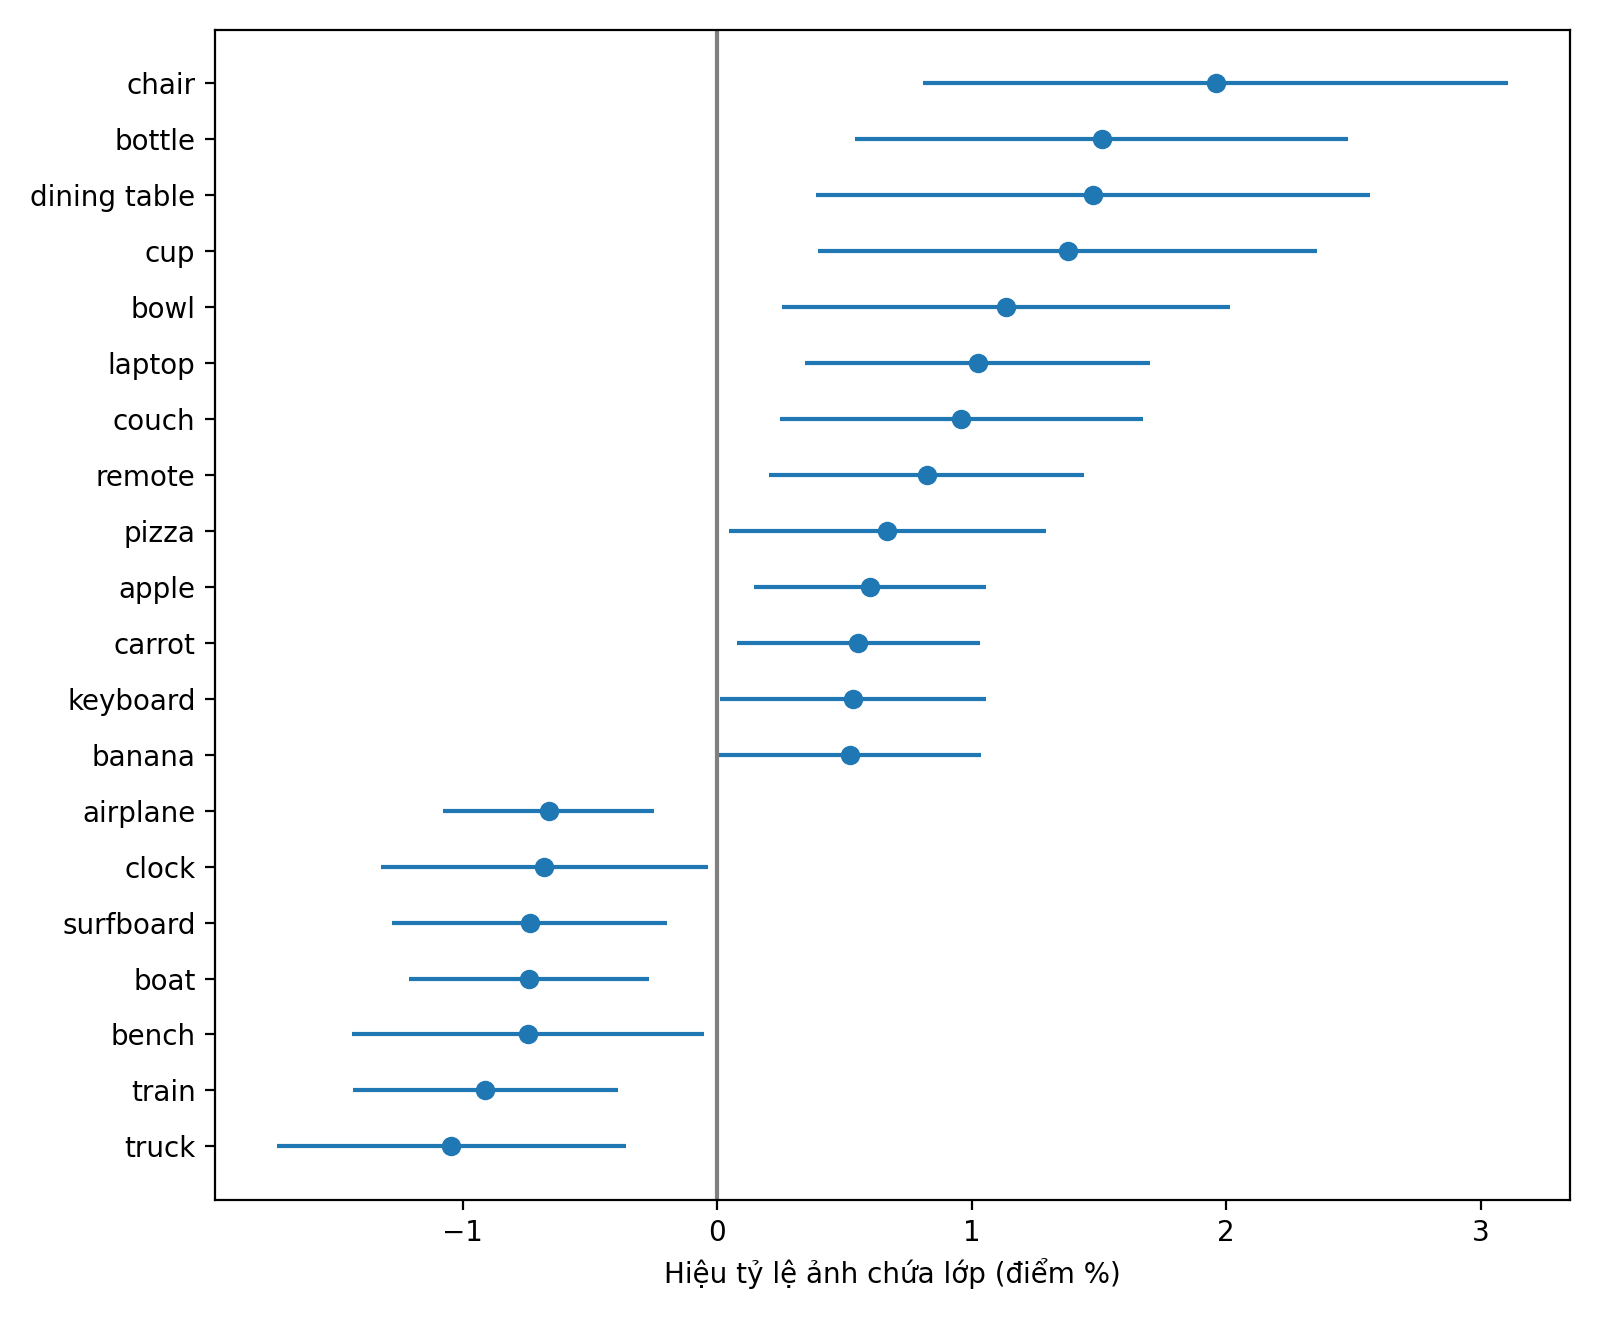

Theo ID của annotation COCO val2017, toàn bộ 2.977 ảnh nhóm này thuộc val2017: **2.977 = 5.000 ảnh val2017 trừ 2.023 ảnh khớp** nguồn đã kiểm tra. Đây là phép nối ID, không phải bảo đảm sạch mọi nguồn huấn luyện.

## 3. Hình học ảnh và token thị giác

### 3.1. Token ảnh SmolVLM2

Số token là số placeholder `<image>` sau processor, không tính token văn bản, hàng/cột hay patch nội bộ.

### Phân bố token ảnh theo processor

<!-- CSV {"path": "eda_results/hgai/report_smol_token_distribution.csv", "title": "Phân bố token ảnh theo processor", "columns": null} -->
| Bộ ảnh | Chế độ | Token ảnh | Số ảnh |
| :--- | :--- | :--- | :--- |
| dev_common_unmatched500 | Chia ô 768 | 243 | 5/500 (1,0%) |
| dev_common_unmatched500 | Chia ô 768 | 405 | 495/500 (99,0%) |
| dev_common_unmatched500 | Tắt chia ô | 81 | 500/500 (100,0%) |
| dev_common_unmatched500 | Chia ô mặc định | 729 | 5/500 (1,0%) |
| dev_common_unmatched500 | Chia ô mặc định | 1.053 | 431/500 (86,2%) |
| dev_common_unmatched500 | Chia ô mặc định | 1.377 | 64/500 (12,8%) |
| eval_common_unmatched500 | Chia ô 768 | 243 | 9/500 (1,8%) |
| eval_common_unmatched500 | Chia ô 768 | 405 | 491/500 (98,2%) |
| eval_common_unmatched500 | Tắt chia ô | 81 | 500/500 (100,0%) |
| eval_common_unmatched500 | Chia ô mặc định | 405 | 1/500 (0,2%) |
| eval_common_unmatched500 | Chia ô mặc định | 729 | 8/500 (1,6%) |
| eval_common_unmatched500 | Chia ô mặc định | 1.053 | 439/500 (87,8%) |
| eval_common_unmatched500 | Chia ô mặc định | 1.377 | 52/500 (10,4%) |
| eval_random500 | Chia ô 768 | 243 | 6/500 (1,2%) |
| eval_random500 | Chia ô 768 | 405 | 494/500 (98,8%) |
| eval_random500 | Tắt chia ô | 81 | 500/500 (100,0%) |
| eval_random500 | Chia ô mặc định | 729 | 6/500 (1,2%) |
| eval_random500 | Chia ô mặc định | 1.053 | 436/500 (87,2%) |
| eval_random500 | Chia ô mặc định | 1.377 | 58/500 (11,6%) |
<!-- /CSV -->

SmolVLM2 nén mỗi ô ảnh thành **81 token** đưa vào LLM; ảnh 640×480 tạo **13 ô = 1.053 token**, gồm các ô cục bộ và ảnh toàn cục. Khi chia ô, ảnh toàn cục được resize vuông nên có méo, còn tile cục bộ giữ gần tỷ lệ hơn. Bảng dưới phân biệt số token, phần ảnh bị cắt/đệm và độ méo; nhiều token hơn không đồng nghĩa có thêm thông tin nguồn.

### Hình học và ngân sách token theo processor

<!-- CSV {"path": "eda_results/hgai/report_processor_geometry.csv", "title": "Hình học và ngân sách token theo processor", "columns": null} -->
| Mô hình/chế độ | Token ảnh | Đệm/cắt | Méo trung vị | Hình học |
| :--- | :--- | :--- | :--- | :--- |
| SmolVLM2 chia ô mặc định | 81 × số ô | 0% crop hợp tile | 1,12 | Pixel nguồn/pixel tile 0,417 (phóng 2,4 lần); ảnh global bị bóp vuông, méo 1,40. |
| SmolVLM2 tắt chia ô | 81 | resize vuông | 1,40 | Thay cả số token lẫn hình học. |
| TinyLLaVA pad384 | 729 | pad P50 26,7% | 1,00 | Giữ tỷ lệ ảnh bằng đệm vuông. |
| LLaVA CLIP336 cắt giữa | 576 | crop P50 26,7% | 1,00 | Bỏ mép ảnh trước encoder. |
<!-- /CSV -->

### 3.2. Cắt giữa, pad và độ phủ object

Nhánh LLaVA theo mã HGAI cắt vuông giữa trước CLIP 336px. Bảng tính theo cặp ảnh–lớp COCO; “mọi instance ở ngoài” là lớp không có instance nào giao vùng cắt; “bị cắt một phần” là có ít nhất một instance còn giao vùng cắt nhưng không nằm trọn trong đó.

### Độ phủ cặp ảnh–lớp sau cắt giữa

<!-- CSV {"path": "eda_results/hgai/report_crop_coverage.csv", "title": "Độ phủ cặp ảnh–lớp sau cắt giữa", "columns": null} -->
| Phạm vi | Số cặp ảnh–lớp | Mọi instance ở ngoài | Bị cắt một phần |
| :--- | :--- | :--- | :--- |
| Toàn val | 116.592 | 5.750/116.592 (4,9%) | 53.501/116.592 (45,9%) |
| eval_random500 | 1.431 | 65/1.431 (4,5%) | 670/1.431 (46,8%) |
<!-- /CSV -->

LLaVA cắt, TinyLLaVA pad, SmolVLM2 giữ toàn ảnh, nên chênh lệch recall giữa ba mô hình có một phần do object có được nhìn thấy hay không.

### 3.3. Độ lệch tâm của vật thể

Độ lệch tâm là khoảng cách tâm bbox tới tâm ảnh, chia cho nửa đường chéo ảnh. Tính trên instance COCO, gồm cả crowd.

Trên 40.137 ảnh có instance, p50/p90/p95/p99 của bbox lớn nhất lần lượt là 0,24/0,54/0,62/0,74; 367 ảnh không có instance. VizWiz chưa có bbox tương ứng.

## 4. Caption và nhãn CHAIR

### 4.1. Độ dài caption tham chiếu

Độ dài caption được đếm bằng tokenizer của từng checkpoint, không gồm prompt hoặc visual token.

### Độ dài caption theo tokenizer

<!-- CSV {"path": "eda_results/hgai/caption_token_summary.csv", "title": "Độ dài caption theo tokenizer", "columns": null} -->
| Bộ dữ liệu | Mô hình | Số ảnh | Trung bình | Nhỏ nhất | P50 | P90 | P95 | P99 | Lớn nhất |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| COCO | SmolVLM2-2.2B | 40.504 | 12 | 7 | 11 | 15 | 17 | 21 | 53 |
| COCO | TinyLLaVA-3.1B | 40.504 | 12 | 7 | 12 | 15 | 17 | 21 | 52 |
| VizWiz-context | SmolVLM2-2.2B | 7.542 | 13 | 7 | 12 | 19 | 22 | 32 | 80 |
| VizWiz-context | TinyLLaVA-3.1B | 7.542 | 13 | 7 | 12 | 18 | 22 | 31 | 76 |
<!-- /CSV -->

### 4.2. Nhãn tham chiếu cho CHAIR

CHAIR dùng hợp nhãn instance và đối tượng từ mọi caption chuẩn. Phép đối chiếu từ vựng trong EDA chỉ chẩn đoán độ phủ của caption được chọn.

Một caption thu hồi 44.390/116.592 (38,1%) lớp instance; hợp mọi caption thu hồi 64.425/116.592 (55,3%).

## 5. Giao thức và thiết kế thí nghiệm

### 5.1. Mốc LLaVA

Mã đánh giá HGAI dùng prompt **“Please help me describe the image in detail.”**, 500 ảnh COCO, giải mã greedy (`do_sample=False`, `num_beams=1`) và tối đa 512 token. Bài báo công bố CHAIR-S **53,0** ở 512 token và **23,8** ở 64 token; đây là số tham chiếu, chưa phải kết quả tái lập ở đây. HGAI của tác giả dùng layer **5–18 tính cả hai đầu**, α=0,5 và gộp mean. [Bảng 2 ở 512 token](https://arxiv.org/html/2411.16724v3#S4.T2), [bảng 3 ở 64 token](https://arxiv.org/html/2411.16724v3#S4.T3).

`eval_data_loader.py` của mã HGAI đưa ảnh vào CLIP 336px theo đường **cắt giữa**; pad vuông là điều kiện khác. LLaVA chỉ có hai hàng kiểm chứng: baseline và HGAI 5–18/α=0,5 trên nhánh mẫu ngẫu nhiên. Kết quả NF4 phải báo riêng với mốc FP16; đối chiếu FP16–NF4 cần cùng checkpoint, ảnh, processor, prompt và giải mã trên khoảng 30 ảnh tại máy đủ VRAM, rồi báo hiệu CHAIR ghép cặp. Checkpoint LLaVA chưa có trọng số đầy đủ trong môi trường này nên hàng kiểm chứng và đối chiếu precision **chưa chạy**.

### 5.2. Điều kiện caption

| Điều kiện | Token tối đa | Vai trò |
| :--- | ---: | :--- |
| detailed512 | 512 | Chính |
| detailed64 | 64 | Đối chứng độ dài |
| concise64 | 64 | Đối chứng prompt |

Mỗi cặp baseline–HGAI giữ nguyên ảnh, prompt, processor, tokenizer và giải mã. CHAIR-S/I đi cùng recall và F1 của object, số token sinh, tỷ lệ chạm trần, tỷ lệ từ chối/rỗng, phần 4-gram lặp, Distinct-1, thời gian và bộ nhớ. **Guard** là ngưỡng loại cấu hình suy giảm chất lượng trên 500 ảnh dev: recall/F1 không giảm quá 0,02; refusal, rỗng, chạm trần và lặp 4-gram không tăng quá 0,05; độ dài trung bình còn ít nhất 50% baseline. Đây là quy tắc chọn đã khóa, không phải kết quả tác giả HGAI. Khoảng tin cậy chênh lệch baseline–HGAI dùng bootstrap **ghép cặp theo ảnh**; CHAIR-I lấy tổng tử số chia tổng mẫu số trong mỗi mẫu bootstrap.

### 5.3. Layer và α của VLM nhỏ

Quy tắc khóa có SHA-256 `7faf7ebde361aed139c4d592537f8f2814e6345bee9ae6c62bd67702ec382fdc`. Chuẩn hóa min–max riêng đường cong VAR và độ nhạy che ảnh trên toàn bộ layer. Nếu một đường cong hằng, chứa giá trị không hữu hạn hoặc có dưới 8 layer thì trả “không tìm thấy ranh giới”. Tìm mọi dải liền mạch tối đại mà cả hai đường cong chuẩn hóa ≥0,60; giữ dải rộng ít nhất max(2, ⌈0,10L⌉) layer. Chọn dải có tổng min(hai giá trị chuẩn hóa) lớn nhất; hòa thì chọn dải bắt đầu sớm nhất. Nếu không có dải đạt điều kiện, trả “không tìm thấy ranh giới”. VAR là tổng attention tới token ảnh ở bước sinh đầu, trung bình qua head và ảnh; độ nhạy che ảnh là sai khác chuẩn hóa của hidden state khi thay ảnh bằng màu RGB (127,127,127).

Trên **SmolVLM2-2.2B, 20 ảnh dev**, đường cong VAR và độ nhạy che ảnh cho kết quả theo quy tắc v1: **không tìm thấy ranh giới**. [Dữ liệu từng layer](eda_results/hgai/layer_curves_summary.csv). VAR ở đây chỉ đo **bước sinh đầu**, với query token đầu cố định; chưa đo trung bình mọi bước sinh. Nếu đo thêm mọi bước, kết quả phải báo riêng. Không dùng điểm CHAIR để xác định dải.

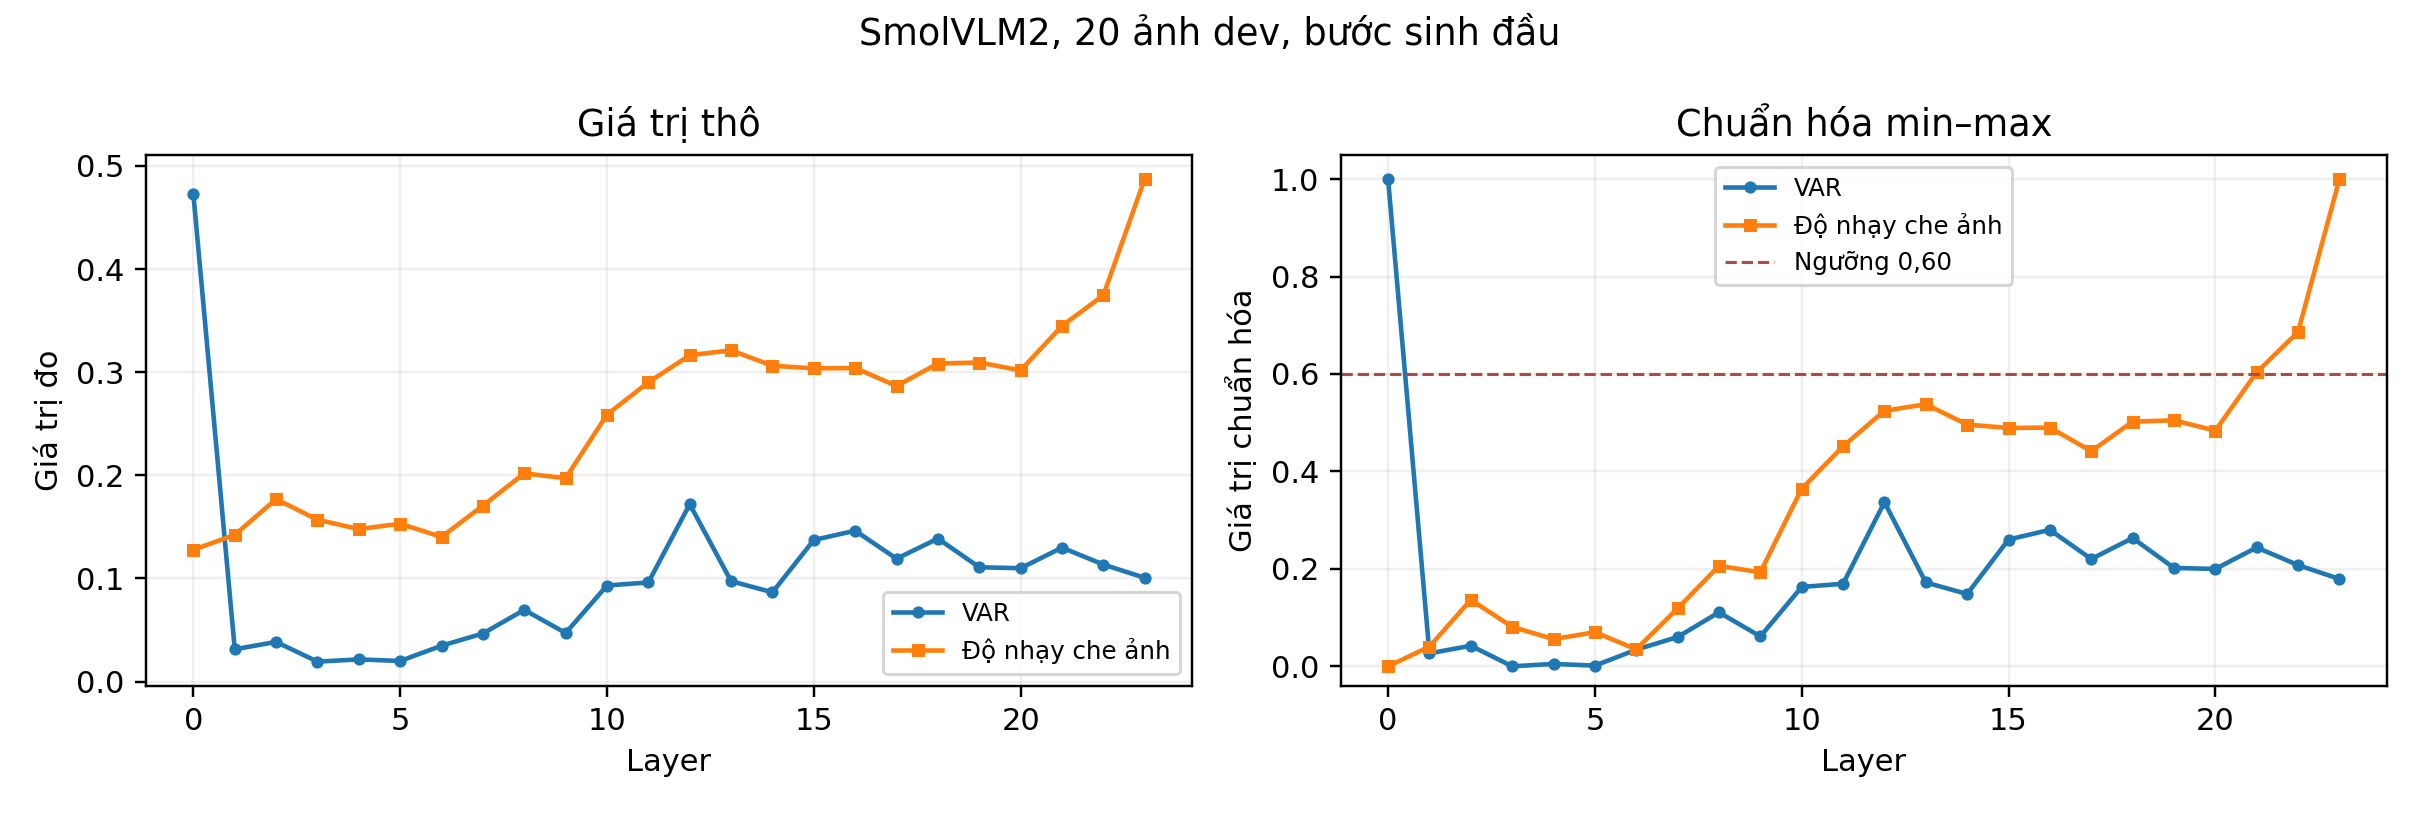

Bảng độ nhạy dưới đây áp cùng phép chọn dải cho ngưỡng 0,50/0,60/0,70; khi bỏ layer 0, min–max được tính lại trên layer 1…L−1. Đây là phân tích mô tả, **không thay quy tắc v1 đã khóa**.

### Độ nhạy của ranh giới theo ngưỡng và layer 0

<!-- CSV {"path": "eda_results/hgai/report_layer_sensitivity.csv", "title": "Độ nhạy của ranh giới theo ngưỡng và layer 0", "columns": null} -->
| Ngưỡng | Layer 0 | Số layer xét | Dải mô tả |
| :--- | :--- | :--- | :--- |
| 0,50 | Có | 24 | không tìm thấy ranh giới |
| 0,50 | Không | 23 | 21–23 |
| 0,60 | Có | 24 | không tìm thấy ranh giới |
| 0,60 | Không | 23 | không tìm thấy ranh giới |
| 0,70 | Có | 24 | không tìm thấy ranh giới |
| 0,70 | Không | 23 | không tìm thấy ranh giới |
<!-- /CSV -->

Quy tắc v1 trên LLaVA-1.5-7B: **chưa chạy**, vì checkpoint trọng số đầy đủ chưa có ở môi trường này; do đó chưa có dải đo để so với mốc 5–18. Không suy dải LLaVA từ đường cong SmolVLM2. Không đề xuất hoặc sử dụng quy tắc v2 trong báo cáo này.

Phép dò α trên 20 ảnh dev, dải layer 5–18, với ba chế độ token ảnh và các liều 0,02/0,035/0,05/0,075/0,10. Tỷ lệ độ dài là trung bình của 20 tỷ số token sinh theo cặp can thiệp/baseline; caption chạm trần 512 token dùng độ dài quan sát. Khoảng cách sửa là Levenshtein ở mức từ, phân tách theo khoảng trắng, giữ chữ hoa và dấu câu. Bảng không dùng điểm CHAIR.

### Phép dò liều α ghép cặp trên 20 ảnh dev

<!-- CSV {"path": "eda_results/hgai/report_alpha_probe20.csv", "title": "Phép dò liều α ghép cặp trên 20 ảnh dev", "columns": null} -->
| Chế độ | α | Tỷ lệ độ dài TB | Co quá nửa | Caption trùng hệt | Khoảng cách sửa từ TB |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Chia ô mặc định | 0,02 | 0,97 | 0/20 (0,0%) | 7/20 (35,0%) | 92,05 |
| Chia ô mặc định | 0,035 | 1,01 | 0/20 (0,0%) | 1/20 (5,0%) | 124,55 |
| Chia ô mặc định | 0,05 | 1,04 | 1/20 (5,0%) | 1/20 (5,0%) | 140,25 |
| Chia ô mặc định | 0,075 | 1,02 | 2/20 (10,0%) | 0/20 (0,0%) | 162,95 |
| Chia ô mặc định | 0,10 | 1,10 | 4/20 (20,0%) | 0/20 (0,0%) | 189,05 |
| Chia ô 768 | 0,02 | 1,16 | 0/20 (0,0%) | 3/20 (15,0%) | 103,95 |
| Chia ô 768 | 0,035 | 1,11 | 1/20 (5,0%) | 1/20 (5,0%) | 156,95 |
| Chia ô 768 | 0,05 | 1,14 | 0/20 (0,0%) | 0/20 (0,0%) | 179,80 |
| Chia ô 768 | 0,075 | 1,14 | 0/20 (0,0%) | 0/20 (0,0%) | 205,75 |
| Chia ô 768 | 0,10 | 1,06 | 0/20 (0,0%) | 0/20 (0,0%) | 199,70 |
| Tắt chia ô | 0,02 | 0,99 | 0/20 (0,0%) | 5/20 (25,0%) | 71,70 |
| Tắt chia ô | 0,035 | 1,04 | 0/20 (0,0%) | 1/20 (5,0%) | 125,45 |
| Tắt chia ô | 0,05 | 1,04 | 1/20 (5,0%) | 1/20 (5,0%) | 132,30 |
| Tắt chia ô | 0,075 | 1,15 | 0/20 (0,0%) | 1/20 (5,0%) | 155,10 |
| Tắt chia ô | 0,10 | 0,97 | 1/20 (5,0%) | 1/20 (5,0%) | 148,70 |
<!-- /CSV -->

Tỷ lệ chạm trần và lặp là chỉ báo suy giảm output, không dùng thay recall/F1. Lặp được đo bằng tỷ phần 4-gram từ lặp trong từng caption, tách từ theo khoảng trắng và đưa về chữ thường.

### Trung vị độ dài, chạm trần và lặp trong phép dò α

<!-- CSV {"path": "eda_results/hgai/report_alpha_probe20_extra.csv", "title": "Trung vị độ dài, chạm trần và lặp trong phép dò α", "columns": null} -->
| Chế độ | α | Trung vị tỷ lệ độ dài | Chạm trần 512 | Có lặp 4-gram | Phần 4-gram lặp TB |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Chia ô mặc định | 0,02 | 1,00 | 2/20 (10,0%) | 18/20 (90,0%) | 0,041 |
| Chia ô mặc định | 0,035 | 1,00 | 2/20 (10,0%) | 17/20 (85,0%) | 0,037 |
| Chia ô mặc định | 0,05 | 0,99 | 2/20 (10,0%) | 15/20 (75,0%) | 0,034 |
| Chia ô mặc định | 0,075 | 0,97 | 2/20 (10,0%) | 15/20 (75,0%) | 0,032 |
| Chia ô mặc định | 0,10 | 0,92 | 2/20 (10,0%) | 14/20 (70,0%) | 0,039 |
| Chia ô 768 | 0,02 | 1,00 | 5/20 (25,0%) | 17/20 (85,0%) | 0,070 |
| Chia ô 768 | 0,035 | 1,00 | 4/20 (20,0%) | 17/20 (85,0%) | 0,055 |
| Chia ô 768 | 0,05 | 1,00 | 4/20 (20,0%) | 17/20 (85,0%) | 0,058 |
| Chia ô 768 | 0,075 | 1,00 | 3/20 (15,0%) | 17/20 (85,0%) | 0,046 |
| Chia ô 768 | 0,10 | 1,00 | 3/20 (15,0%) | 17/20 (85,0%) | 0,039 |
| Tắt chia ô | 0,02 | 1,00 | 1/20 (5,0%) | 13/20 (65,0%) | 0,033 |
| Tắt chia ô | 0,035 | 1,00 | 1/20 (5,0%) | 15/20 (75,0%) | 0,029 |
| Tắt chia ô | 0,05 | 1,00 | 0/20 (0,0%) | 12/20 (60,0%) | 0,037 |
| Tắt chia ô | 0,075 | 1,00 | 2/20 (10,0%) | 14/20 (70,0%) | 0,104 |
| Tắt chia ô | 0,10 | 0,94 | 1/20 (5,0%) | 12/20 (60,0%) | 0,070 |
<!-- /CSV -->

Lưới α khóa trước khi đo CHAIR trên 500 ảnh dev: 0,02, 0,035, 0,05, 0,075, 0,10. Guard đã khóa trên toàn bộ 500 ảnh dev quyết định cấu hình hợp lệ.

Phép dò tương tự trên **bczhou/TinyLLaVA-3.1B**, 10 ảnh dev, NF4, pad384, layer 5–18, prompt detailed512. Các tỷ lệ độ dài được ghép theo cùng ảnh baseline; đây chỉ là phép dò output, không dùng CHAIR để chọn α.

### Phép dò liều α của TinyLLaVA trên 10 ảnh dev

<!-- CSV {"path": "eda_results/hgai/report_tiny_alpha_probe10.csv", "title": "Phép dò liều α của TinyLLaVA trên 10 ảnh dev", "columns": null} -->
| α | Trung vị tỷ lệ độ dài | Token sinh TB | Co quá nửa | Chạm trần 512 | Có lặp 4-gram |
| :--- | :--- | :--- | :--- | :--- | :--- |
| 0,00 | 1,00 | 182,9 | 0/10 (0,0%) | 0/10 (0,0%) | 3/10 (30,0%) |
| 0,02 | 1,00 | 172,8 | 0/10 (0,0%) | 0/10 (0,0%) | 4/10 (40,0%) |
| 0,035 | 1,00 | 186,4 | 0/10 (0,0%) | 0/10 (0,0%) | 4/10 (40,0%) |
| 0,05 | 1,03 | 200,0 | 0/10 (0,0%) | 0/10 (0,0%) | 4/10 (40,0%) |
| 0,075 | 1,01 | 202,5 | 0/10 (0,0%) | 0/10 (0,0%) | 4/10 (40,0%) |
| 0,10 | 1,00 | 195,6 | 0/10 (0,0%) | 0/10 (0,0%) | 4/10 (40,0%) |
<!-- /CSV -->

### 5.4. Đối chứng layer và ngân sách tính toán

Dải ngẫu nhiên phải rút **ít nhất 20 lần**, mỗi dải có đúng chiều rộng của dải đang đối chiếu, trên cùng tập con **125 ảnh dev** cố định; khi v1 không trả dải, dùng chiều rộng 14 layer của nhánh 5–18 làm tham chiếu mô tả. Quét oracle trên 125 ảnh dev chỉ là trần tham chiếu, không dùng eval để chọn. Hai nhánh định trước gồm **layer 5–18 tuyệt đối** và dải co theo độ sâu từ LLaVA 32 layer: lấy khoảng nửa mở [5,19), chuyển sang độ sâu L bằng `start=floor(5L/32)`, `end=ceil(19L/32)-1` (hai đầu tính vào). Vì vậy SmolVLM2 24 layer dùng dải co 3–14; TinyLLaVA 32 layer có dải co trùng 5–18. Điều kiện “mọi layer” được báo riêng.

Số giờ bên dưới là **quy đổi từ tốc độ pilot cùng mô hình/chế độ**: Smol detailed512 mặc định 20 ảnh, chia ô 768 và tắt chia ô mỗi chế độ 20 ảnh, POPE 60 câu hỏi mỗi biến thể; Tiny dùng pilot detailed512 khi hoàn tất. Các ô “chưa ước tính” không được gán tốc độ của mô hình khác. Tổng giờ toàn chiến dịch chỉ xác định sau khi có tốc độ Tiny/LLaVA và hai điều kiện prompt 64 token.

### Ngân sách theo thời gian pilot

<!-- CSV {"path": "eda_results/hgai/report_compute_budget.csv", "title": "Ngân sách theo thời gian pilot", "columns": null} -->
| Mô hình | Nhánh | Cấu hình | Ảnh/câu mỗi cấu hình | Tổng lượt sinh | Giây/lượt từ pilot | Giờ quy đổi |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| Smol | Dev baseline + lưới α (dải kiểm chứng) | 6 | 500 | 3.000 | 20,16 | 16,80 |
| Smol | 20 dải ngẫu nhiên cùng độ rộng | 20 | 125 | 2.500 | 20,16 | 14,00 |
| Smol | Quét oracle 24 layer | 24 | 125 | 3.000 | 20,16 | 16,80 |
| Smol | Dải 5–18 và dải co, 5 liều | 10 | 125 | 1.250 | 20,16 | 7,00 |
| Smol | Mọi layer | 1 | 125 | 125 | 20,16 | 0,70 |
| Smol | Eval lọc: 512 token, baseline/HGAI | 2 | 500 | 1.000 | 20,16 | 5,60 |
| Smol | Eval ngẫu nhiên: 512 token, baseline/HGAI | 2 | 500 | 1.000 | 20,16 | 5,60 |
| Smol | Eval lọc: chia ô 768, baseline/HGAI | 2 | 500 | 1.000 | 17,92 | 4,98 |
| Smol | Eval lọc: tắt chia ô, baseline/HGAI | 2 | 500 | 1.000 | 14,53 | 4,04 |
| Smol | Eval lọc: detailed64/concise64, 2 nhánh | 4 | 500 | 2.000 | chưa đo | chưa ước tính |
| Smol | POPE: 3 biến thể, baseline/HGAI | 6 | 3.000 | 18.000 | 2,67 | 13,34 |
| Tiny | Dev baseline + 5 liều | 6 | 500 | 3.000 | 12,71 | 10,59 |
| Tiny | 20 dải ngẫu nhiên cùng độ rộng | 20 | 125 | 2.500 | 12,71 | 8,83 |
| Tiny | Quét oracle 32 layer | 32 | 125 | 4.000 | 12,71 | 14,12 |
| Tiny | Dải 5–18 và dải co (trùng ở 32 layer) | 5 | 125 | 625 | 12,71 | 2,21 |
| Tiny | Mọi layer | 1 | 125 | 125 | 12,71 | 0,44 |
| Tiny | Eval lọc: 512/64/concise64, 2 nhánh | 6 | 500 | 3.000 | chưa đo | chưa ước tính |
| Tiny | Eval ngẫu nhiên: 512, baseline/HGAI | 2 | 500 | 1.000 | chưa đo | chưa ước tính |
| Tiny | POPE: 3 biến thể, baseline/HGAI | 6 | 3.000 | 18.000 | chưa đo | chưa ước tính |
| LLaVA | Eval ngẫu nhiên: baseline và 5–18/α=0,5 | 2 | 500 | 1.000 | chưa đo | chưa ước tính |
| LLaVA | Đối chiếu FP16–NF4 trên 30 ảnh | 2 | 30 | 60 | chưa đo | chưa ước tính |
| Tổng | Phần có tốc độ pilot / toàn kế hoạch | — | — | 67.185 | các hàng còn thiếu chưa đo | 125,04 giờ phần quy đổi; tổng đầy đủ chưa xác định |
<!-- /CSV -->

Tập con 125 ảnh dev dùng seed 42; các cấu hình dẫn đầu sau quét thô mới chạy đủ 500 ảnh dev và qua guard trước hai bộ eval. Ngân sách gồm cả 3 mức token ảnh Smol, hai bộ eval, POPE và hàng LLaVA; số giờ là ước lượng quy mô, chưa phải thời gian hoàn thành đo được.

### 5.5. POPE kiểm tra chéo

POPE dùng ba bộ COCO random, popular và adversarial chính thức, mỗi bộ 3.000 câu hỏi cho baseline và HGAI đã khóa từ dev. Giữ nhãn và negative sampling của POPE; báo accuracy, precision, recall, F1, yes-rate và số câu hỏi/ảnh. Không coi 500 ảnh CHAIR là một bộ POPE mới. Bootstrap POPE lấy mẫu theo **ảnh**, giữ mọi câu hỏi của cùng ảnh trong một cụm. POPE và hai bộ eval không dùng để chọn α hoặc dải layer.

### 5.6. Checkpoint TinyLLaVA

Đối chiếu hai định danh checkpoint Phi-2 và SigLIP.

### Đối chiếu checkpoint TinyLLaVA

<!-- CSV {"path": "eda_results/hgai/report_tiny_checkpoint_comparison.csv", "title": "Đối chiếu checkpoint TinyLLaVA", "columns": null} -->
| Checkpoint | Cấu hình | Trọng số / hash | Nạp trong môi trường hiện tại | Can thiệp attention |
| :--- | :--- | :--- | :--- | :--- |
| bczhou/TinyLLaVA-3.1B | Phi-2, SigLIP; 32 layer; pad 384 | 12.747.668.712 byte; SHA-256: adac2836b85d1267a4f4bf6f8a0ed77bc6ed46870daac94100bee1522b203f34 / aa3028a5e43d1cc5cb73fd976c36c2030dbfcc7e6d1f0904b85db25b96b1a021 / 414bf35a7b5a081cdc2157bf5130ee0435c7eac6d6b148079373f342175bc5a3 | Đã nạp và sinh caption trên 1 ảnh dev. | Đã xác nhận modified_calls > 0 trên 1 ảnh dev. |
| tinyllava/TinyLLaVA-Phi-2-SigLIP-3.1B | Phi-2, SigLIP; 32 layer; ảnh vuông 384; model_type=tinyllava | 6.434.958.600 byte; SHA-256: 0ef383f3357694d5432fd3a45b2ac45bfc9e8ccb9eb4ee8368a86fde5274cc1e / 9c658ee49bb2b64f89ffd09291b136ff292a800c1563f57bbf1110ffddc3dee7 | Không tương thích adapter tiny_llava_phi hiện tại; chưa thử đường remote code. | Adapter hiện tại chưa nối lớp TinyLlavaForConditionalGeneration; cần port riêng. |
<!-- /CSV -->

Ở ảnh dev thử với điều kiện detailed64 và α=0,02, adapter ghi 896 lần gọi attention được sửa. Caption của ảnh thử trùng baseline. [Dữ liệu kiểm chứng](eda_results/hgai/tiny_checkpoint_validation.json).

Shard bczhou đã tải và đối chiếu SHA-256 tại máy này. [Nguồn và từng shard](eda_results/hgai/tiny_checkpoint_public_metadata.json).

Checkpoint được chọn: `bczhou/TinyLLaVA-3.1B` cho nhánh pad và adapter Phi-2 hiện tại. Cấu hình checkpoint `tinyllava/TinyLLaVA-Phi-2-SigLIP-3.1B` khai báo lớp mô hình riêng; kết luận về adapter của checkpoint này là suy ra từ cấu hình, chưa kiểm tra forward. [Cấu hình chính thức](https://huggingface.co/tinyllava/TinyLLaVA-Phi-2-SigLIP-3.1B/blob/a5501098449440fa319da7b0814dc53bf8530f14/config.json).

## Phụ lục A. Bảng và hình nền

### A.1. Nhóm từ chỉ người

Đồng nghĩa CHAIR được khớp theo cụm dài trước trên một caption chọn cho mỗi ảnh.

### Nhóm từ chỉ người COCO và VizWiz

<!-- CSV {"path": "eda_results/hgai/report_person_reference.csv", "title": "Nhóm từ chỉ người COCO và VizWiz", "columns": null} -->
| Bộ dữ liệu | Caption chọn | Lượt nhắc nhóm người | Caption nhắc nhóm người |
| :--- | :--- | :--- | :--- |
| MS-COCO val2014 | 40.504/40.504 (100,0%) | 16.557 | 15.196/40.504 (37,5%) |
| VizWiz val | 7.542/7.750 (97,3%) | 678 | 653/7.542 (8,7%) |
<!-- /CSV -->

### A.2. Đủ 80 lớp COCO trong phân tích dịch chuyển

### Tỷ lệ ảnh chứa từng lớp COCO-80

<!-- CSV {"path": "eda_results/hgai/report_object_shift.csv", "title": "Tỷ lệ ảnh chứa từng lớp COCO-80", "columns": null} -->
| Lớp | Nhóm 2.977 ảnh | Toàn val2014 | Hiệu (điểm %) | CI 95% (điểm %) |
| :--- | :--- | :--- | :--- | :--- |
| person | 1.606/2.977 (53,9%) | 21.634/40.504 (53,4%) | 0,5 | [-1,2; 2,3] |
| bicycle | 68/2.977 (2,3%) | 1.114/40.504 (2,8%) | -0,5 | [-1,0; 0,1] |
| car | 279/2.977 (9,4%) | 4.180/40.504 (10,3%) | -0,9 | [-2,0; 0,1] |
| motorcycle | 88/2.977 (3,0%) | 1.219/40.504 (3,0%) | -0,1 | [-0,6; 0,5] |
| airplane | 42/2.977 (1,4%) | 840/40.504 (2,1%) | -0,7 | [-1,1; -0,2] |
| bus | 93/2.977 (3,1%) | 1.350/40.504 (3,3%) | -0,2 | [-0,8; 0,4] |
| train | 67/2.977 (2,3%) | 1.281/40.504 (3,2%) | -0,9 | [-1,4; -0,4] |
| truck | 120/2.977 (4,0%) | 2.056/40.504 (5,1%) | -1,0 | [-1,7; -0,4] |
| boat | 55/2.977 (1,8%) | 1.048/40.504 (2,6%) | -0,7 | [-1,2; -0,3] |
| traffic light | 99/2.977 (3,3%) | 1.437/40.504 (3,5%) | -0,2 | [-0,8; 0,4] |
| fire hydrant | 53/2.977 (1,8%) | 592/40.504 (1,5%) | 0,3 | [-0,1; 0,8] |
| stop sign | 39/2.977 (1,3%) | 589/40.504 (1,5%) | -0,1 | [-0,5; 0,3] |
| parking meter | 19/2.977 (0,6%) | 261/40.504 (0,6%) | 0,0 | [-0,3; 0,3] |
| bench | 122/2.977 (4,1%) | 1.961/40.504 (4,8%) | -0,7 | [-1,4; -0,1] |
| bird | 72/2.977 (2,4%) | 1.121/40.504 (2,8%) | -0,3 | [-0,9; 0,2] |
| cat | 118/2.977 (4,0%) | 1.480/40.504 (3,7%) | 0,3 | [-0,4; 1,0] |
| dog | 110/2.977 (3,7%) | 1.521/40.504 (3,8%) | -0,1 | [-0,7; 0,6] |
| horse | 73/2.977 (2,5%) | 1.001/40.504 (2,5%) | 0,0 | [-0,6; 0,5] |
| sheep | 38/2.977 (1,3%) | 489/40.504 (1,2%) | 0,1 | [-0,3; 0,5] |
| cow | 49/2.977 (1,6%) | 666/40.504 (1,6%) | 0,0 | [-0,4; 0,4] |
| elephant | 50/2.977 (1,7%) | 714/40.504 (1,8%) | -0,1 | [-0,5; 0,4] |
| bear | 29/2.977 (1,0%) | 341/40.504 (0,8%) | 0,1 | [-0,2; 0,5] |
| zebra | 50/2.977 (1,7%) | 677/40.504 (1,7%) | 0,0 | [-0,4; 0,5] |
| giraffe | 56/2.977 (1,9%) | 849/40.504 (2,1%) | -0,2 | [-0,7; 0,3] |
| backpack | 143/2.977 (4,8%) | 1.832/40.504 (4,5%) | 0,3 | [-0,5; 1,0] |
| umbrella | 102/2.977 (3,4%) | 1.393/40.504 (3,4%) | 0,0 | [-0,6; 0,6] |
| handbag | 173/2.977 (5,8%) | 2.272/40.504 (5,6%) | 0,2 | [-0,6; 1,0] |
| tie | 95/2.977 (3,2%) | 1.288/40.504 (3,2%) | 0,0 | [-0,6; 0,6] |
| suitcase | 67/2.977 (2,3%) | 876/40.504 (2,2%) | 0,1 | [-0,4; 0,6] |
| frisbee | 58/2.977 (1,9%) | 757/40.504 (1,9%) | 0,1 | [-0,4; 0,6] |
| skis | 78/2.977 (2,6%) | 993/40.504 (2,5%) | 0,2 | [-0,4; 0,7] |
| snowboard | 31/2.977 (1,0%) | 533/40.504 (1,3%) | -0,3 | [-0,6; 0,1] |
| sports ball | 96/2.977 (3,2%) | 1.445/40.504 (3,6%) | -0,3 | [-1,0; 0,3] |
| kite | 53/2.977 (1,8%) | 727/40.504 (1,8%) | 0,0 | [-0,5; 0,4] |
| baseball bat | 55/2.977 (1,8%) | 799/40.504 (2,0%) | -0,1 | [-0,6; 0,3] |
| baseball glove | 52/2.977 (1,7%) | 845/40.504 (2,1%) | -0,3 | [-0,8; 0,1] |
| skateboard | 81/2.977 (2,7%) | 1.092/40.504 (2,7%) | 0,0 | [-0,5; 0,6] |
| surfboard | 73/2.977 (2,5%) | 1.292/40.504 (3,2%) | -0,7 | [-1,3; -0,2] |
| tennis racket | 103/2.977 (3,5%) | 1.193/40.504 (2,9%) | 0,5 | [-0,1; 1,1] |
| bottle | 259/2.977 (8,7%) | 2.912/40.504 (7,2%) | 1,5 | [0,5; 2,5] |
| wine glass | 76/2.977 (2,6%) | 872/40.504 (2,2%) | 0,4 | [-0,1; 0,9] |
| cup | 266/2.977 (8,9%) | 3.061/40.504 (7,6%) | 1,4 | [0,4; 2,4] |
| fork | 100/2.977 (3,4%) | 1.173/40.504 (2,9%) | 0,5 | [-0,2; 1,1] |
| knife | 122/2.977 (4,1%) | 1.410/40.504 (3,5%) | 0,6 | [-0,1; 1,3] |
| spoon | 94/2.977 (3,2%) | 1.189/40.504 (2,9%) | 0,2 | [-0,4; 0,8] |
| bowl | 210/2.977 (7,1%) | 2.397/40.504 (5,9%) | 1,1 | [0,3; 2,0] |
| banana | 69/2.977 (2,3%) | 728/40.504 (1,8%) | 0,5 | [0,0; 1,0] |
| apple | 54/2.977 (1,8%) | 491/40.504 (1,2%) | 0,6 | [0,1; 1,1] |
| sandwich | 68/2.977 (2,3%) | 818/40.504 (2,0%) | 0,3 | [-0,2; 0,8] |
| orange | 50/2.977 (1,7%) | 568/40.504 (1,4%) | 0,3 | [-0,2; 0,7] |
| broccoli | 51/2.977 (1,7%) | 670/40.504 (1,7%) | 0,1 | [-0,4; 0,5] |
| carrot | 59/2.977 (2,0%) | 578/40.504 (1,4%) | 0,6 | [0,1; 1,0] |
| hot dog | 32/2.977 (1,1%) | 452/40.504 (1,1%) | 0,0 | [-0,4; 0,3] |
| pizza | 102/2.977 (3,4%) | 1.117/40.504 (2,8%) | 0,7 | [0,0; 1,3] |
| donut | 41/2.977 (1,4%) | 523/40.504 (1,3%) | 0,1 | [-0,3; 0,5] |
| cake | 86/2.977 (2,9%) | 969/40.504 (2,4%) | 0,5 | [-0,1; 1,1] |
| chair | 382/2.977 (12,8%) | 4.404/40.504 (10,9%) | 2,0 | [0,8; 3,1] |
| couch | 135/2.977 (4,5%) | 1.448/40.504 (3,6%) | 1,0 | [0,2; 1,7] |
| potted plant | 120/2.977 (4,0%) | 1.540/40.504 (3,8%) | 0,2 | [-0,4; 0,9] |
| bed | 88/2.977 (3,0%) | 1.292/40.504 (3,2%) | -0,2 | [-0,8; 0,4] |
| dining table | 335/2.977 (11,3%) | 3.960/40.504 (9,8%) | 1,5 | [0,4; 2,6] |
| toilet | 98/2.977 (3,3%) | 1.185/40.504 (2,9%) | 0,4 | [-0,2; 1,0] |
| tv | 128/2.977 (4,3%) | 1.577/40.504 (3,9%) | 0,4 | [-0,3; 1,1] |
| laptop | 121/2.977 (4,1%) | 1.232/40.504 (3,0%) | 1,0 | [0,3; 1,7] |
| mouse | 61/2.977 (2,0%) | 674/40.504 (1,7%) | 0,4 | [-0,1; 0,9] |
| remote | 101/2.977 (3,4%) | 1.041/40.504 (2,6%) | 0,8 | [0,2; 1,4] |
| keyboard | 71/2.977 (2,4%) | 750/40.504 (1,9%) | 0,5 | [0,0; 1,1] |
| cell phone | 135/2.977 (4,5%) | 1.695/40.504 (4,2%) | 0,3 | [-0,4; 1,1] |
| microwave | 36/2.977 (1,2%) | 512/40.504 (1,3%) | -0,1 | [-0,4; 0,3] |
| oven | 74/2.977 (2,5%) | 989/40.504 (2,4%) | 0,0 | [-0,5; 0,6] |
| toaster | 6/2.977 (0,2%) | 74/40.504 (0,2%) | 0,0 | [-0,1; 0,2] |
| sink | 128/2.977 (4,3%) | 1.574/40.504 (3,9%) | 0,4 | [-0,3; 1,1] |
| refrigerator | 70/2.977 (2,4%) | 790/40.504 (2,0%) | 0,4 | [-0,1; 0,9] |
| book | 144/2.977 (4,8%) | 1.828/40.504 (4,5%) | 0,3 | [-0,4; 1,1] |
| clock | 105/2.977 (3,5%) | 1.704/40.504 (4,2%) | -0,7 | [-1,3; 0,0] |
| vase | 100/2.977 (3,4%) | 1.200/40.504 (3,0%) | 0,4 | [-0,2; 1,0] |
| scissors | 20/2.977 (0,7%) | 302/40.504 (0,7%) | -0,1 | [-0,4; 0,2] |
| teddy bear | 58/2.977 (1,9%) | 724/40.504 (1,8%) | 0,2 | [-0,3; 0,6] |
| hair drier | 8/2.977 (0,3%) | 70/40.504 (0,2%) | 0,1 | [-0,1; 0,3] |
| toothbrush | 19/2.977 (0,6%) | 341/40.504 (0,8%) | -0,2 | [-0,5; 0,1] |
<!-- /CSV -->

### A.3. Siêu danh mục và lệch tâm

### 12 siêu danh mục COCO val2014

<!-- CSV {"path": "eda_results/hgai/report_supercategories.csv", "title": "12 siêu danh mục COCO val2014", "columns": null} -->
| Siêu danh mục | Số instance |
| :--- | :--- |
| person | 88.153/291.875 (30,2%) |
| vehicle | 32.574/291.875 (11,2%) |
| kitchen | 29.445/291.875 (10,1%) |
| furniture | 26.296/291.875 (9,0%) |
| animal | 21.806/291.875 (7,5%) |
| food | 21.423/291.875 (7,3%) |
| sports | 16.786/291.875 (5,8%) |
| indoor | 15.795/291.875 (5,4%) |
| accessory | 15.483/291.875 (5,3%) |
| electronic | 9.822/291.875 (3,4%) |
| outdoor | 9.710/291.875 (3,3%) |
| appliance | 4.582/291.875 (1,6%) |
<!-- /CSV -->

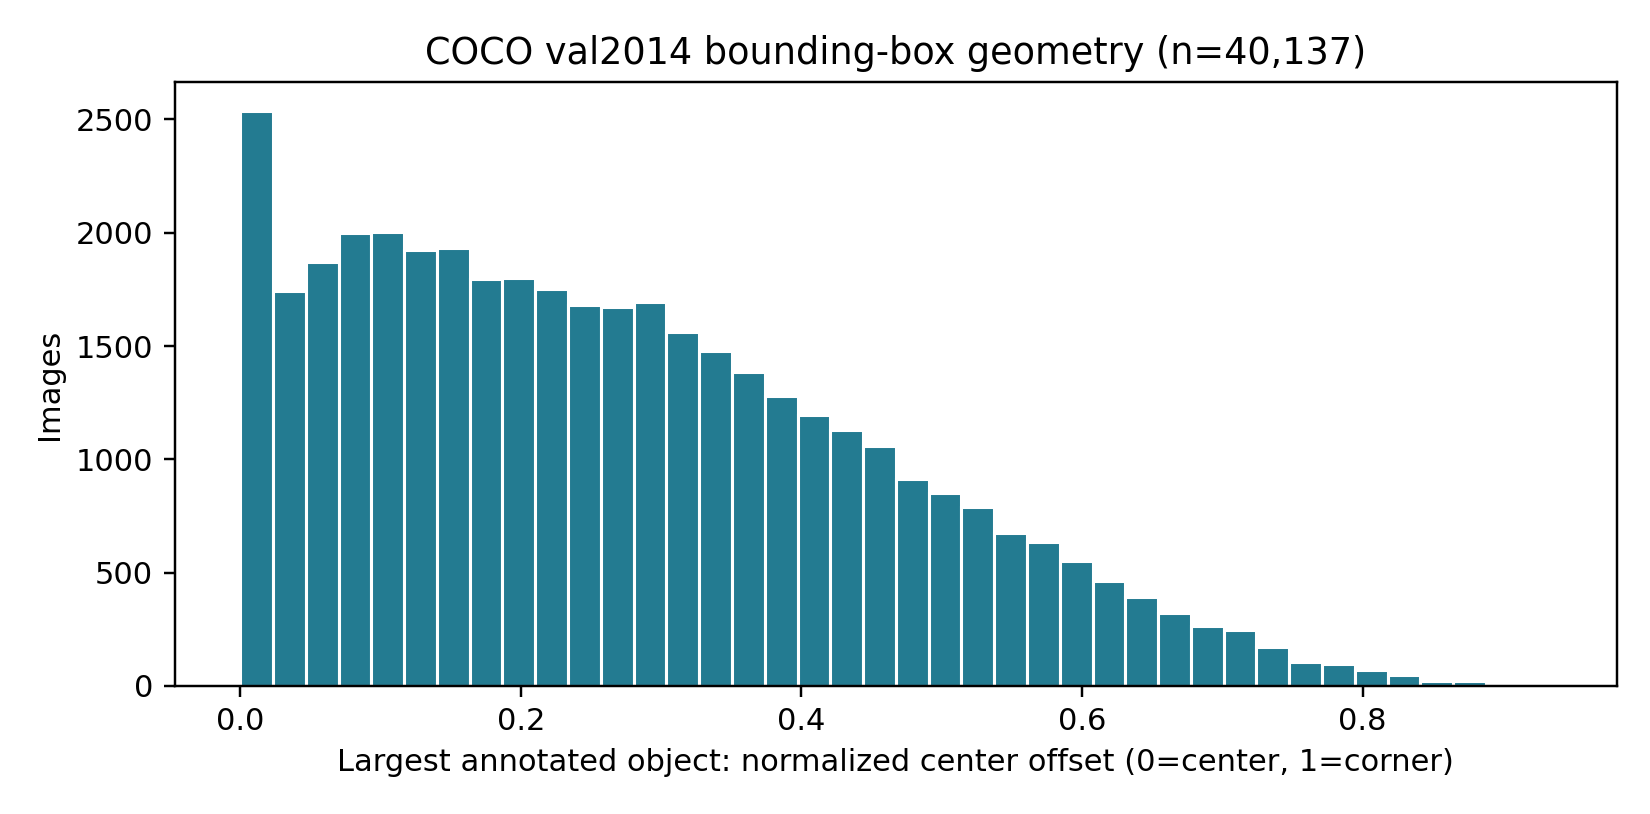

## Tài liệu nguồn

1. [HGAI: Devils in Middle Layers, bài báo](https://arxiv.org/abs/2411.16724), [mã đánh giá và data loader của tác giả](https://github.com/ZhangqiJiang07/middle_layers_indicating_hallucinations).
2. [SmolVLM2-2.2B-Instruct, model card và processor](https://huggingface.co/HuggingFaceTB/SmolVLM2-2.2B-Instruct); [recipe SmolVLM2](https://github.com/huggingface/smollm/tree/main/vision/smolvlm2).
3. [TinyLLaVA bczhou](https://huggingface.co/bczhou/TinyLLaVA-3.1B), [TinyLLaVA Phi-2 SigLIP](https://huggingface.co/tinyllava/TinyLLaVA-Phi-2-SigLIP-3.1B), [bài TinyLLaVA](https://arxiv.org/abs/2402.14289).
4. [LLaVA-1.5-7B](https://huggingface.co/liuhaotian/llava-v1.5-7b), [LLaVA mix665K](https://huggingface.co/datasets/liuhaotian/LLaVA-Instruct-150K), [ShareGPT4V](https://huggingface.co/datasets/Lin-Chen/ShareGPT4V), [OneVision](https://huggingface.co/datasets/lmms-lab/LLaVA-OneVision-Data).
5. [CHAIR](https://aclanthology.org/D18-1437/), [POPE và dữ liệu câu hỏi chính thức](https://github.com/RUCAIBox/POPE).
6. [COCO](https://cocodataset.org/), [Visual Genome](https://visualgenome.org/), [VizWiz](https://vizwiz.org/tasks-and-datasets/image-quality-issues/).